<a href="https://colab.research.google.com/github/elenamaggiore/Thesis_Elena_Maggiore/blob/datasets/DATASETS_Big_Five_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATASET: Big Five dataset

This code will create the Big Five dataset by merging together the MyPersonality dataset and the Twitter dataset, used as train set for the binary classification tasks related to Big Five dichotomies.

Libraries:

In [1]:
import pandas as pd
import os
import os
import json
import xml.etree.ElementTree as ET
import pandas as pd
import pprint
import json
import pandas as pd

import os
import json
import numpy as np
import pandas as pd
from collections import defaultdict
import re, gc, time, html, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, confusion_matrix)
from transformers import AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup

from google.colab import drive
drive.mount('/content/drive')




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading datasets:

In [2]:


# Define the file paths as strings
mypersonality_path = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/mypersonality_final.csv"

# Function to load CSV safely, trying standard and alternative encodings
def load_csv(path):
    try:
        return pd.read_csv(path, encoding='utf-8')
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding='latin1')

# Load the datasets
mypersonality = load_csv(mypersonality_path)

# Print success message and shapes
print("mypersonality loaded successfully. Shape:", mypersonality.shape)

train_dir = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15-author-profiling-training-dataset-english-2015-04-23'
test_dir = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15-author-profiling-test-dataset2-english-2015-04-23'

def inspect_dir(directory):
    if os.path.exists(directory):
        items = os.listdir(directory)
        print(f"Directory: {directory}")
        print(f"Total items: {len(items)}")
        print(f"Sample items: {items[:10]}\n")
    else:
        print(f"Directory not found: {directory}\n")

inspect_dir(train_dir)
inspect_dir(test_dir)

mypersonality loaded successfully. Shape: (9917, 20)
Directory: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15-author-profiling-training-dataset-english-2015-04-23
Total items: 153
Sample items: ['truth.txt', '78fb5696-dc1c-4ea9-b4e4-ae67acd7de72.xml', 'dde4cfc8-f4cf-47be-8d9c-21b3b7f63098.xml', 'fd7c89ad-deb5-4445-99c5-bf4c698ee371.xml', '60468a75-1938-4366-abaa-5ad1cc1b0b8e.xml', '5def4eb3-e861-4864-a2f2-669680902007.xml', 'e78b60f0-b114-4238-a0b2-dbd52ab12b99.xml', 'c7537d18-440b-451a-991a-22cb30f28d3a.xml', '69ba7d3d-eac7-4878-9d3f-984353a91c15.xml', 'c0f2ba6b-200e-44fb-ac60-81084eec9daa.xml']

Directory: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15-author-profiling-test-dataset2-english-2015-04-23
Total items: 143
Sample items: ['93ec14bd-97c6-460c-870d-40d0839e9e81.xml', '1bccb2ff-2818-44ba-ada6-3393915183f5.xml', 'b5cabb17-22cb-4e38-9047-ed4fb6fc18ad.xml', 'e5f6483c-31bd-48b3-aed1-24b96801b3b3.xml', '4d44835a-6fa8-4abb-8047-2bda762cc

PAN15 dataset needs parsing before being loaded:

In [3]:
def parse_pan15_dataset(directory):
    # The truth file is typically named 'truth.txt' inside the dataset directory
    truth_file_path = os.path.join(directory, 'truth.txt')
    if not os.path.exists(truth_file_path):
        # Try finding any .txt file in the folder just in case
        txt_files = [f for f in os.listdir(directory) if f.endswith('.txt')]
        if txt_files:
            truth_file_path = os.path.join(directory, txt_files[0])
        else:
            raise FileNotFoundError(f"Truth metadata file not found in {directory}")

    # Parse truth metadata
    # PAN 15 truth.txt format is typically: author_id:::gender:::age:::extrovert:::neurotic:::agreeable:::conscientious:::open
    authors_metadata = {}
    with open(truth_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split(':::')
            if len(parts) >= 8:
                author_id = parts[0]
                authors_metadata[author_id] = {
                    "author_id": author_id,
                    "gender": parts[1],
                    "age_group": parts[2],
                    "extroverted": float(parts[3]),
                    "neurotic": float(parts[4]),
                    "agreeable": float(parts[5]),
                    "conscientious": float(parts[6]),
                    "open": float(parts[7])
                }

    # Parse XML posts for each author
    parsed_records = []
    for filename in os.listdir(directory):
        if filename.endswith('.xml'):
            author_id = filename[:-4] # Strip '.xml' extension
            xml_path = os.path.join(directory, filename)

            try:
                tree = ET.parse(xml_path)
                root = tree.getroot()

                # Extract posts
                posts = [document.text for document in root.findall('.//document') if document.text is not None]

                # Retrieve metadata
                meta = authors_metadata.get(author_id, {
                    "author_id": author_id,
                    "gender": None,
                    "age_group": None,
                    "extroverted": None,
                    "neurotic": None,
                    "agreeable": None,
                    "conscientious": None,
                    "open": None
                })

                # Create merged record
                record = meta.copy()
                record["posts"] = posts
                parsed_records.append(record)
            except Exception as e:
                print(f"Error reading XML file {filename}: {e}")

    return parsed_records

# Load and parse both sets
train_parsed = parse_pan15_dataset(train_dir)
test_parsed = parse_pan15_dataset(test_dir)

# Combine datasets and add a split indicator
for r in train_parsed:
    r["split"] = "train"
for r in test_parsed:
    r["split"] = "test"

all_pan15_data = train_parsed + test_parsed
print(f"Successfully parsed {len(all_pan15_data)} profiles (Train: {len(train_parsed)}, Test: {len(test_parsed)})")

# Save the formatted datasets to JSON files on Google Drive
output_json_path = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15_parsed.json"

with open(output_json_path, 'w', encoding='utf-8') as f:
    json.dump(all_pan15_data, f, indent=4, ensure_ascii=False)

print(f"The parsed data has been exported successfully to a pretty JSON file at:\n{output_json_path}")

Successfully parsed 294 profiles (Train: 152, Test: 142)
The parsed data has been exported successfully to a pretty JSON file at:
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/pan15_parsed.json


In [4]:

# Load the parsed JSON
with open(output_json_path, 'r', encoding='utf-8') as f:
    parsed_data = json.load(f)

# Flatten the data to match the 'mypersonality' format (one row per post/status)
flattened_records = []
for author in parsed_data:
    for post in author.get("posts", []):
        record = {
            "#AUTHID": author["author_id"],
            "STATUS": post.strip(),
            "sEXT": author["extroverted"],
            "sNEU": author["neurotic"],
            "sAGR": author["agreeable"],
            "sCON": author["conscientious"],
            "sOPN": author["open"],
            "GENDER": author["gender"],
            "AGE_GROUP": author["age_group"],
            "SPLIT": author["split"]
        }
        flattened_records.append(record)

# Create DataFrame
pan15_df = pd.DataFrame(flattened_records)

print("PAN15 DataFrame created successfully!")
print("Shape:", pan15_df.shape)
display(pan15_df.head())

PAN15 DataFrame created successfully!
Shape: (27344, 10)


,#AUTHID,STATUS,sEXT,sNEU,sAGR,sCON,sOPN,GENDER,AGE_GROUP,SPLIT
0,78fb5696-dc1c-4ea9-b4e4-ae67acd7de72,I just became the mayor of Porta Romana on @us...,0.5,0.1,0.1,0.1,0.1,F,25-34,train
1,78fb5696-dc1c-4ea9-b4e4-ae67acd7de72,I just became the mayor of Via Torino on @user...,0.5,0.1,0.1,0.1,0.1,F,25-34,train
2,78fb5696-dc1c-4ea9-b4e4-ae67acd7de72,Mornig buongiorno! Milano in grey today!,0.5,0.1,0.1,0.1,0.1,F,25-34,train
3,78fb5696-dc1c-4ea9-b4e4-ae67acd7de72,@username dude i ve just read Your email so g...,0.5,0.1,0.1,0.1,0.1,F,25-34,train
4,78fb5696-dc1c-4ea9-b4e4-ae67acd7de72,Photo: via James Dean was a conservative http:...,0.5,0.1,0.1,0.1,0.1,F,25-34,train


Merge between the datasets: one row is one user

In [5]:
# ============================================================
# CONFIGURATION
# One row = one user.
# Posts are stored as a list, not as separate rows.
# ============================================================

OUTPUT_DIR = (
    "/content/drive/MyDrive/Thesis_Elena_Maggiore/"
    "Datasets/Big Five"
)

TRAITS = ["EXT", "NEU", "AGR", "CON", "OPN"]

# PAN-AP-2015 field names -> canonical Big Five names
TWITTER_TRAIT_FIELDS = {
    "EXT": ["extroverted", "sEXT", "scoreEXT"],
    "NEU": ["neurotic", "sNEU", "scoreNEU"],
    "AGR": ["agreeable", "sAGR", "scoreAGR"],
    "CON": ["conscientious", "sCON", "scoreCON"],
    "OPN": ["open", "openness", "sOPN", "scoreOPN"],
}


# ============================================================
# GENERAL HELPERS
# ============================================================

def normalize_column_name(name):
    """Normalize names for robust column matching."""
    return "".join(ch.lower() for ch in str(name)
                   if ch.isalnum())


def find_column(df, aliases, required=False):
    """Return the actual DataFrame column matching an alias."""
    lookup = {
        normalize_column_name(col): col
        for col in df.columns
    }

    for alias in aliases:
        key = normalize_column_name(alias)
        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Required column not found. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def get_dict_value(record, aliases, default=None):
    """Retrieve a value from a dictionary using alternative keys."""
    lookup = {
        normalize_column_name(key): value
        for key, value in record.items()
    }

    for alias in aliases:
        key = normalize_column_name(alias)
        if key in lookup:
            return lookup[key]

    return default


def first_valid(series):
    """Return the first non-missing, non-empty scalar value."""
    for value in series:
        if value is None:
            continue
        try:
            if pd.isna(value):
                continue
        except (TypeError, ValueError):
            pass

        if isinstance(value, str) and not value.strip():
            continue

        return value

    return None


def numeric_median(series):
    """Return the median of valid numeric values."""
    values = pd.to_numeric(series, errors="coerce").dropna()
    return float(values.median()) if len(values) else np.nan


def parse_post_list(value):
    """
    Return a list of posts.
    Handles lists, JSON-encoded lists and individual strings.
    """
    if isinstance(value, (list, tuple)):
        values = value

    elif value is None:
        return []

    elif isinstance(value, float) and np.isnan(value):
        return []

    elif isinstance(value, str):
        text = value.strip()

        if not text:
            return []

        # Parse a JSON list if one is stored as a string.
        if text.startswith("["):
            try:
                decoded = json.loads(text)
                if isinstance(decoded, list):
                    values = decoded
                else:
                    values = [text]
            except (json.JSONDecodeError, TypeError):
                values = [text]
        else:
            values = [text]

    else:
        values = [value]

    # Preserve the original order and repeated posts.
    return [
        str(post).strip()
        for post in values
        if post is not None
        and not (isinstance(post, float) and np.isnan(post))
        and str(post).strip()
    ]


def median_of_values(values):
    """Median for a list containing potentially missing values."""
    return numeric_median(pd.Series(values, dtype="object"))


def pan_score_to_1_5(value):
    """
    Convert PAN-AP-2015 scores from [-0.5, 0.5] to [1, 5].
    Preserve already-1-to-5 values.
    Missing values remain missing.

    IMPORTANT:
    This aligns numeric ranges, not psychometric instruments.
    """
    if pd.isna(value):
        return np.nan

    value = float(value)

    if -0.500001 <= value <= 0.500001:
        return 4.0 * value + 3.0

    if 1.0 <= value <= 5.0:
        return value

    # Do not silently transform unexpected values.
    return value


# ============================================================
# 1. FACEBOOK: myPersonality / WCPR13
# Aggregate all STATUS records by author.
# ============================================================

if "mypersonality" not in globals():
    raise NameError(
        "DataFrame 'mypersonality' not found. "
        "Run the cell that loads mypersonality_final.csv first."
    )

fb = mypersonality.copy()
fb.columns = [str(c).strip() for c in fb.columns]

fb_id_col = find_column(
    fb,
    ["#AUTHID", "AUTHID", "author_id", "user_id", "author"],
    required=True
)

fb_text_col = find_column(
    fb,
    ["STATUS", "status", "post", "text"],
    required=True
)

# Find available Big Five score columns.
fb_score_cols = {
    trait: find_column(
        fb,
        [f"s{trait}", f"score{trait}"]
    )
    for trait in TRAITS
}

# Optional demographic and network information.
fb_metadata_cols = {
    "GENDER": find_column(fb, ["GENDER", "gender"]),
    "AGE_GROUP": find_column(fb, ["AGE_GROUP", "age_group"]),
    "NETWORKSIZE": find_column(
        fb, ["NETWORKSIZE", "network_size"]
    ),
    "BETWEENNESS": find_column(
        fb, ["BETWEENNESS", "betweenness"]
    ),
    "BROKERAGE": find_column(
        fb, ["BROKERAGE", "brokerage"]
    ),
    "TRANSITIVITY": find_column(
        fb, ["TRANSITIVITY", "transitivity"]
    ),
}

fb[fb_id_col] = fb[fb_id_col].astype("string").str.strip()

fb = fb[
    fb[fb_id_col].notna()
    & fb[fb_id_col].ne("")
].copy()

facebook_records = []

for author_id, group in fb.groupby(fb_id_col, sort=False):

    row = {
        "user_id": f"facebook:{author_id}",
        "source": "facebook",
        "score_instrument": "WCPR13 / myPersonality",
        "GENDER": None,
        "AGE_GROUP": None,
        "NETWORKSIZE": np.nan,
        "BETWEENNESS": np.nan,
        "BROKERAGE": np.nan,
        "TRANSITIVITY": np.nan,
        "ORIGINAL_SPLIT": None,
    }

    # One score per user, rather than one score per status.
    for trait in TRAITS:
        col = fb_score_cols[trait]

        if col is not None:
            raw_score = numeric_median(group[col])
        else:
            raw_score = np.nan

        row[f"s{trait}"] = raw_score
        row[f"s{trait}_raw"] = raw_score

    # Keep available metadata.
    for target_col, original_col in fb_metadata_cols.items():
        if original_col is not None:
            row[target_col] = first_valid(group[original_col])

    # Store all statuses in a single list.
    row["posts"] = parse_post_list(
        group[fb_text_col].tolist()
    )

    facebook_records.append(row)


# ============================================================
# 2. TWITTER: PAN-AP-2015
# Prefer the already parsed user-level data.
# Fall back to pan15_df if necessary.
# ============================================================

twitter_source_records = []

if (
    "all_pan15_data" in globals()
    and isinstance(all_pan15_data, list)
    and len(all_pan15_data) > 0
):
    # These records already contain one dictionary per author.
    twitter_source_records = all_pan15_data.copy()

elif (
    "pan15_df" in globals()
    and isinstance(pan15_df, pd.DataFrame)
    and not pan15_df.empty
):
    # Fallback: aggregate the post-level DataFrame by author.
    tw = pan15_df.copy()
    tw.columns = [str(c).strip() for c in tw.columns]

    tw_id_col = find_column(
        tw,
        ["author_id", "#AUTHID", "AUTHID", "user_id"],
        required=True
    )

    tw_text_col = find_column(
        tw,
        ["posts", "STATUS", "status", "text"],
        required=True
    )

    for author_id, group in tw.groupby(tw_id_col, sort=False):

        record = {
            "author_id": author_id,
            "posts": group[tw_text_col].tolist(),
        }

        for trait in TRAITS:
            col = find_column(
                group,
                TWITTER_TRAIT_FIELDS[trait]
            )
            record[TWITTER_TRAIT_FIELDS[trait][0]] = (
                numeric_median(group[col])
                if col is not None
                else np.nan
            )

        gender_col = find_column(group, ["gender", "GENDER"])
        age_col = find_column(group, ["age_group", "AGE_GROUP"])
        split_col = find_column(group, ["split", "SPLIT"])

        record["gender"] = (
            first_valid(group[gender_col])
            if gender_col is not None else None
        )
        record["age_group"] = (
            first_valid(group[age_col])
            if age_col is not None else None
        )
        record["split"] = (
            first_valid(group[split_col])
            if split_col is not None else None
        )

        twitter_source_records.append(record)

else:
    raise NameError(
        "Neither 'all_pan15_data' nor 'pan15_df' is available. "
        "Run the PAN-AP-2015 parsing cells first."
    )


# Combine records sharing the same Twitter author ID, if any.
twitter_by_author = defaultdict(list)

for record in twitter_source_records:
    author_id = get_dict_value(
        record,
        ["author_id", "#AUTHID", "AUTHID", "user_id"]
    )

    if author_id is None or not str(author_id).strip():
        continue

    twitter_by_author[str(author_id).strip()].append(record)


twitter_records = []

for author_id, records in twitter_by_author.items():

    row = {
        "user_id": f"twitter:{author_id}",
        "source": "twitter",
        "score_instrument": "PAN-AP-2015 / BFI-10",
        "GENDER": None,
        "AGE_GROUP": None,
        "NETWORKSIZE": np.nan,
        "BETWEENNESS": np.nan,
        "BROKERAGE": np.nan,
        "TRANSITIVITY": np.nan,
    }

    all_posts = []
    original_splits = []

    for record in records:
        all_posts.extend(
            parse_post_list(
                get_dict_value(record, ["posts", "STATUS", "text"])
            )
        )

        split_value = get_dict_value(
            record, ["split", "SPLIT"]
        )
        if split_value is not None and not pd.isna(split_value):
            original_splits.append(str(split_value))

    # One score per author.
    for trait in TRAITS:

        values = []

        for record in records:
            value = get_dict_value(
                record,
                TWITTER_TRAIT_FIELDS[trait]
            )

            if value is not None:
                try:
                    value = float(value)
                    if np.isfinite(value):
                        values.append(value)
                except (ValueError, TypeError):
                    pass

        raw_score = (
            float(np.median(values))
            if values else np.nan
        )

        row[f"s{trait}_raw"] = raw_score
        row[f"s{trait}"] = pan_score_to_1_5(raw_score)

    for target_col, aliases in {
        "GENDER": ["gender", "GENDER"],
        "AGE_GROUP": ["age_group", "AGE_GROUP", "age"],
    }.items():

        row[target_col] = first_valid(
            pd.Series([
                get_dict_value(record, aliases)
                for record in records
            ])
        )

    row["ORIGINAL_SPLIT"] = (
        "|".join(dict.fromkeys(original_splits))
        if original_splits else None
    )

    row["posts"] = all_posts

    twitter_records.append(row)


# ============================================================
# 3. MERGE: one row per user
# ============================================================

merged_df = pd.DataFrame(
    facebook_records + twitter_records
)

# Explicit output schema. 'source' must remain the final column.
output_columns = [
    "user_id",
    "GENDER",
    "AGE_GROUP",
    "sEXT", "sNEU", "sAGR", "sCON", "sOPN",
    "sEXT_raw", "sNEU_raw", "sAGR_raw", "sCON_raw", "sOPN_raw",
    "score_instrument",
    "NETWORKSIZE", "BETWEENNESS", "BROKERAGE", "TRANSITIVITY",
    "ORIGINAL_SPLIT",
    "posts",
    "source",
]

for col in output_columns:
    if col not in merged_df.columns:
        merged_df[col] = np.nan

merged_df = merged_df[output_columns].copy()

# Ensure one row per user.
if merged_df["user_id"].duplicated().any():
    duplicates = merged_df.loc[
        merged_df["user_id"].duplicated(keep=False),
        "user_id"
    ].tolist()

    raise ValueError(
        "Duplicate user IDs detected after aggregation: "
        f"{duplicates[:10]}"
    )

# Keep missing metadata as null rather than fabricated values.
merged_df["posts"] = merged_df["posts"].apply(
    lambda value: value if isinstance(value, list) else []
)

# ============================================================
# 4. QUALITY CHECKS
# ============================================================

print("=" * 65)
print("MERGE COMPLETED — USER-LEVEL DATASET")
print("=" * 65)

print("Final shape:", merged_df.shape)
print("Unique users:", merged_df["user_id"].nunique())

print("\nUsers by source:")
print(merged_df["source"].value_counts(dropna=False))

print("\nUsers without any posts:",
      int(merged_df["posts"].map(len).eq(0).sum()))

print("\nAverage posts per user:")
print(
    merged_df.groupby("source")["posts"]
    .apply(lambda values: values.map(len).mean())
)

print("\nMissing Big Five scores by source:")
print(
    merged_df.groupby("source")[
        ["sEXT", "sNEU", "sAGR", "sCON", "sOPN"]
    ].apply(lambda frame: frame.isna().sum())
)

# Warn if Facebook score columns do not appear to be on a 1–5 scale.
for trait in TRAITS:
    values = merged_df.loc[
        merged_df["source"] == "facebook", f"s{trait}"
    ].dropna()

    if len(values) and not values.between(1, 5).all():
        print(
            f"WARNING: Facebook s{trait} values are not all "
            "between 1 and 5. Check the original score scale."
        )

assert merged_df.columns[-1] == "source"
assert merged_df["user_id"].is_unique

# ============================================================
# 5. SAVE CSV AND JSON
# CSV stores 'posts' as a JSON-encoded string.
# JSON preserves 'posts' as an actual array.
# ============================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_path = os.path.join(
    OUTPUT_DIR,
    "facebook_twitter_bigfive_user_level.csv"
)

json_path = os.path.join(
    OUTPUT_DIR,
    "facebook_twitter_bigfive_user_level.json"
)

csv_output = merged_df.copy()
csv_output["posts"] = csv_output["posts"].apply(
    lambda value: json.dumps(value, ensure_ascii=False)
)

csv_output.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

merged_df.to_json(
    json_path,
    orient="records",
    force_ascii=False,
    indent=2
)

print("\nSaved files:")
print(csv_path)
print(json_path)

print("\nPreview:")
display(merged_df.head(3))


MERGE COMPLETED — USER-LEVEL DATASET
Final shape: (544, 21)
Unique users: 544

Users by source:
source
twitter     294
facebook    250
Name: count, dtype: int64

Users without any posts: 0

Average posts per user:
source
facebook    39.668000
twitter     93.006803
Name: posts, dtype: float64

Missing Big Five scores by source:
          sEXT  sNEU  sAGR  sCON  sOPN
source                                
facebook     0     0     0     0     0
twitter      0     0     0     0     0

Saved files:
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/facebook_twitter_bigfive_user_level.csv
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Big Five/facebook_twitter_bigfive_user_level.json

Preview:


,user_id,GENDER,AGE_GROUP,sEXT,sNEU,sAGR,sCON,sOPN,sEXT_raw,sNEU_raw,...,sCON_raw,sOPN_raw,score_instrument,NETWORKSIZE,BETWEENNESS,BROKERAGE,TRANSITIVITY,ORIGINAL_SPLIT,posts,source
0,facebook:b7b7764cfa1c523e4e93ab2a79a946c4,None,None,2.65,3.00,3.15,3.25,4.40,2.65,3.00,...,3.25,4.40,WCPR13 / myPersonality,180.0,14861.6,15661.0,0.10,None,"[likes the sound of thunder., is so sleepy it'...",facebook
1,facebook:318bf822d4f2bd3920367560218619c0,None,None,4.50,4.00,3.00,4.50,3.75,4.50,4.00,...,4.50,3.75,WCPR13 / myPersonality,318.0,49024.8,49584.0,0.06,None,"[has bed bugs..... ewwwww!, and mosquito bites...",facebook
2,facebook:ecbddbfe00e0f83cfdb802a7186061c7,None,None,4.30,2.15,3.60,3.30,4.10,4.30,2.15,...,3.30,4.10,WCPR13 / myPersonality,739.0,267574.0,270029.0,0.07,None,"[is stuck on Band-Aid brand, cuz Band-Aid's st...",facebook


Balance between classes:

In [6]:

traits = ["EXT", "NEU", "AGR", "CON", "OPN"]

diagnostic_df = merged_df.copy()

for trait in traits:
    score_col = f"s{trait}_raw"

    # Preliminary diagnostic only:
    # high/low defined relative to each platform's median.
    diagnostic_df[f"{trait}_highlow"] = (
        diagnostic_df[score_col]
        >= diagnostic_df.groupby("source")[score_col]
            .transform("median")
    ).astype("Int64")

    print(f"\n{'=' * 45}")
    print(f"Trait: {trait}")

    counts = pd.crosstab(
        diagnostic_df["source"],
        diagnostic_df[f"{trait}_highlow"],
        margins=True,
        dropna=False
    )

    print(counts)

    counts_by_source = pd.crosstab(
        diagnostic_df["source"],
        diagnostic_df[f"{trait}_highlow"],
        normalize="index"
    )

    print("\nClass proportions by source:")
    print(counts_by_source.round(3))



Trait: EXT
EXT_highlow    0    1  All
source                    
facebook     122  128  250
twitter      142  152  294
All          264  280  544

Class proportions by source:
EXT_highlow      0      1
source                   
facebook     0.488  0.512
twitter      0.483  0.517

Trait: NEU
NEU_highlow    0    1  All
source                    
facebook     125  125  250
twitter      138  156  294
All          263  281  544

Class proportions by source:
NEU_highlow      0      1
source                   
facebook     0.500  0.500
twitter      0.469  0.531

Trait: AGR
AGR_highlow    0    1  All
source                    
facebook     125  125  250
twitter       72  222  294
All          197  347  544

Class proportions by source:
AGR_highlow      0      1
source                   
facebook     0.500  0.500
twitter      0.245  0.755

Trait: CON
CON_highlow    0    1  All
source                    
facebook     120  130  250
twitter      142  152  294
All          262  282  544

Class pro

General parameters:

In [7]:
SEED = 11
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Output folders (OUTPUT_DIR is defined in the merge cell above)
OUT_DIR = Path(OUTPUT_DIR) / "preprocessing_outputs"
AUG_DIR = OUT_DIR / "synthetic"           # synthetic examples (one CSV per trait + progress file)
FT_DIR = OUT_DIR / "gpt2_finetuned"       # fine-tuned generator
for d in (OUT_DIR / "figures", OUT_DIR / "tables", AUG_DIR):
    d.mkdir(parents=True, exist_ok=True)

TRAIT_NAMES = {"EXT": "Extraversion", "NEU": "Neuroticism", "AGR": "Agreeableness",
               "CON": "Conscientiousness", "OPN": "Openness"}
SOURCES = ["facebook", "twitter"]

# One binary task per Big Five trait. Key = trait code = name of the 0/1 label column.
# First pole is coded 1, second pole is coded 0. Cut-off: median of the user's own platform (see STEP TWO).
DIMS = {t: ("high", "low") for t in TRAITS}

URL_TOKEN = "URL"          # URL mention placeholder
MIN_POST_WORDS = 3
MIN_POSTS_PER_USER = 10

SPLIT = {"train": 0.70, "val": 0.30}
EXAMPLE_POSTS = 10         # consecutive posts per example

Device: cuda


Oversampling parameters (LLMs, embedding parameters):

In [8]:
GEN_MODEL = "gpt2"         # base model: it is FINE-TUNED on the training examples before generating
GEN_WINDOW_POSTS = 5       # posts of a real training example used as prompt (after the class-control code)
PROMPT_MAX_TOKENS = 150    # context window size
GEN_TEMP, GEN_TOP_K, GEN_TOP_P = 0.7, 50, 0.95
NUM_BEAMS = 1
NO_REPEAT_NGRAM = 2
GEN_LEN_RATIO, GEN_MIN_NEW, GEN_MAX_NEW = 0.75, 40, 100
MIN_SYN_WORDS = 10         # generated texts shorter than this are discarded
TARGET_BALANCE = 1.0       # fully balance the training examples of each dimension
MAX_SYN_PER_DIM = 12000    # compute cap on synthetic examples per dimension
GEN_BATCH_SIZE = 32
SAVE_EVERY = 1024          # checkpoint (and resume) granularity, in generated examples

# Fine-tuning (on the TRAIN examples only, label-masked text)
FT_MAX_TOKENS = 256        # max length of a fine-tuning sequence (control code + masked example)
FT_EPOCHS = 2
FT_LR = 5e-5
FT_BATCH_SIZE = 16
FT_WARMUP_FRAC = 0.05
FT_MAX_EXAMPLES = None     # e.g. 15000 to cap the training time; None = all training examples
FT_PPL_SAMPLE = 500        # validation examples used only to monitor perplexity (never for training)

Parameters of the classifier used for verification:

In [9]:
TFIDF_KW = dict(ngram_range=(1, 2), min_df=2, max_df=0.8, max_features=50000, sublinear_tf=True)
CLF_C = 1.0

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
_FIG_N = _TAB_N = 0

Label masking parameters:

In [10]:
MASKING = True

TRAIT_TOKEN, FRAMEWORK_TOKEN = "TRAIT_MENTION", "FRAMEWORK_MENTION"

# Explicit trait-name vocabulary, one regex per Big Five trait: self-disclosure of the label
# (the analogue of "I'm an INTJ"). Generic adjectives such as "open" or "agreeable" are NOT masked.
TRAIT_LEX = {
    "EXT": re.compile(r"(?<![A-Za-z_])(?:extr[ao]|intro)(?:version|verts?|verted)(?![A-Za-z_])", re.I),
    "NEU": re.compile(r"(?<![A-Za-z_])(?:neurotic(?:s|ism)?|emotional(?:ly)?\s+stab(?:le|ility))(?![A-Za-z_])", re.I),
    "AGR": re.compile(r"(?<![A-Za-z_])(?:dis)?agreeableness(?![A-Za-z_])", re.I),
    "CON": re.compile(r"(?<![A-Za-z_])conscientious(?:ness)?(?![A-Za-z_])", re.I),
    "OPN": re.compile(r"(?<![A-Za-z_])(?:openness(?:\s+to\s+(?:new\s+)?(?:experiences?|ideas?))?"
                      r"|open\s+to\s+(?:new\s+)?experiences?)(?![A-Za-z_])", re.I),
}

# Names of the model / test the labels come from (the analogue of "cognitive function" talk). "OCEAN" is case-sensitive.
RE_FRAMEWORK = re.compile(
    r"(?<![A-Za-z_])(?:big[\s-]?(?:five|5)(?:\s+personality)?|five[\s-]?factor(?:\s+model)?|ffm"
    r"|neo[\s-]?(?:pi|ffi)(?:[\s-]?r)?|bfi(?:-\d+)?|(?-i:OCEAN))(?![A-Za-z_])", re.I)

RE_URL = re.compile(r"(?:https?://|www\.)\S+", re.I)

Tokenizer with class-control codes:

In [11]:
CTRL_SOURCE = {s: f"<|{s}|>" for s in SOURCES}
CTRL_TRAIT = {(t, v): f"<|{t.lower()}_{'high' if v else 'low'}|>" for t in TRAITS for v in (0, 1)}
CTRL_ALL = list(CTRL_SOURCE.values()) + list(CTRL_TRAIT.values())   # 2 platform codes + 10 trait codes

def make_ctrl(r):
    # control codes prepended to every fine-tuning / generation text: platform + high/low level of each trait
    # r: any mapping with "source" and the five 0/1 trait columns (dict or DataFrame row)
    return " ".join([CTRL_SOURCE[r["source"]]] + [CTRL_TRAIT[(t, int(r[t]))] for t in TRAITS])

tok = AutoTokenizer.from_pretrained(GEN_MODEL)
tok.add_special_tokens({"additional_special_tokens": CTRL_ALL})
tok.pad_token = tok.eos_token
tok.padding_side = "left"                            # left for generation (switched to right only while fine-tuning)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Functions:

In [12]:
# UTILITIES:
def savefig(name):
    global _FIG_N
    _FIG_N += 1
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / f"fig{_FIG_N:02d}_{name}.png", dpi=300, bbox_inches="tight")
    plt.show(); plt.close()

def savetab(df, name, index=True):
    global _TAB_N
    _TAB_N += 1
    df.to_csv(OUT_DIR / "tables" / f"tab{_TAB_N:02d}_{name}.csv", index=index, encoding="utf-8-sig")


# MASKING:
def mask_text(t):
    # Returns (masked_text, n_trait_mentions, n_framework_mentions)
    t, n_f = RE_FRAMEWORK.subn(FRAMEWORK_TOKEN, t)
    n_t = 0
    for rx in TRAIT_LEX.values():
        t, k = rx.subn(TRAIT_TOKEN, t); n_t += k
    return t, n_t, n_f

def clean_post(t):
    t = html.unescape(str(t))
    t = RE_URL.sub(f" {URL_TOKEN} ", t)
    return re.sub(r"\s+", " ", t).strip()

def dedup_key(t):
    return re.sub(r"[^a-z0-9]+", " ", t.lower()).strip()


# TRAIN/VALIDATION SPLIT:

def _safe_strat(s, min_n=3):
    # profiles with fewer than min_n users are pooled so that stratification never fails
    s = s.where(s.map(s.value_counts()) >= min_n, "RARE")
    return s if s.value_counts().min() >= 2 else None

def stratified_user_split(users, strat, fractions, seed):
    tr, rest = train_test_split(users, test_size=1 - fractions["train"], stratify=_safe_strat(strat), random_state=seed)
    va, te = train_test_split(rest, test_size=fractions["test"] / (fractions["val"] + fractions["test"]),
                              stratify=_safe_strat(strat.loc[rest.index]), random_state=seed)
    return tr, va, te

def make_examples(posts_df, k):
    out, ex_id = [], 0
    for uid, g in posts_df.sort_values(["user_id", "post_idx"]).groupby("user_id", sort=False):
        o, m = g["text_orig"].tolist(), g["text_masked"].tolist()
        starts = list(range(0, len(o), k))
        if len(starts) > 1 and len(o) - starts[-1] < max(1, k // 2):
            starts = starts[:-1]
        for j, s in enumerate(starts):
            e = starts[j + 1] if j + 1 < len(starts) else len(o)
            out.append((f"e{ex_id:06d}", uid, j, " ".join(o[s:e]), " ".join(m[s:e]), m[s:e]))
            ex_id += 1
    return pd.DataFrame(out, columns=["ex_id", "user_id", "ex_idx", "text_orig", "text_masked", "posts_masked"])


# BASELINE
def majority_baseline(y_train, y_eval):
    maj = int(y_train.mean() >= 0.5)
    pred = np.full(len(y_eval), maj)
    return dict(acc=accuracy_score(y_eval, pred), macro_f1=f1_score(y_eval, pred, average="macro", zero_division=0))


# OVERSAMPLING:
@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True, truncation=True, max_length=PROMPT_MAX_TOKENS).to(DEVICE)
    n_in = enc["attention_mask"].sum(1).float().mean().item()
    max_new = int(np.clip(GEN_LEN_RATIO * n_in, GEN_MIN_NEW, GEN_MAX_NEW))
    out = gen_model.generate(**enc, do_sample=True, top_k=GEN_TOP_K, top_p=GEN_TOP_P, temperature=GEN_TEMP,
                             num_beams=NUM_BEAMS, no_repeat_ngram_size=NO_REPEAT_NGRAM, max_new_tokens=max_new,
                             pad_token_id=tok.eos_token_id)
    return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

def build_plan(dim, n_needed, minority_label, k_seed):
    # Deterministic list of (source_ex_id, source_user_id, source_profile, prompt) -> allows resuming
    pool = tr_ex[tr_ex[dim] == minority_label].reset_index(drop=True)
    rng = random.Random(SEED + k_seed)
    plan = []
    for _ in range(n_needed):
        r = pool.iloc[rng.randrange(len(pool))]
        posts = r["posts_masked"]
        s = rng.randrange(0, max(1, len(posts) - GEN_WINDOW_POSTS + 1))
        prompt = f"{make_ctrl(r)} " + " ".join(posts[s:s + GEN_WINDOW_POSTS])   # control codes + real masked window
        plan.append((r["ex_id"], r["user_id"], r["profile"], prompt))
    return plan

def generate_synthetic(dim, k_seed):
    n_needed = int(imb.loc[dim, "needed_synthetic"])
    if n_needed <= 0:
        print(f"[{dim}] nothing to generate"); return
    minority_label = int(tr_ex[dim].mean() < 0.5)
    f_csv, f_prog = AUG_DIR / f"syn_{dim}.csv", AUG_DIR / f"syn_{dim}.progress.json"
    done = json.loads(f_prog.read_text())["done"] if f_prog.exists() else 0
    plan = build_plan(dim, n_needed, minority_label, k_seed)
    print(f"[{dim}] needed={n_needed:,} | already done={done:,} | minority label={minority_label}")
    t0 = time.time()
    for b0 in range(done, n_needed, SAVE_EVERY):
        block = plan[b0:b0 + SAVE_EVERY]
        order = sorted(range(len(block)), key=lambda i: len(block[i][3]))   # similar lengths per batch
        texts = [None] * len(block)
        for i in range(0, len(order), GEN_BATCH_SIZE):
            idx = order[i:i + GEN_BATCH_SIZE]
            for j, t in zip(idx, generate_batch([block[j][3] for j in idx])):
                texts[j] = t
        recs = []
        for (src_ex, src_user, src_profile, _), t in zip(block, texts):
            masked, _, _ = mask_text(clean_post(t))
            if len(masked.split()) >= MIN_SYN_WORDS:
                recs.append(dict(syn_id=f"s_{dim}_{len(recs)}_{b0}", dim=dim, source_ex_id=src_ex,
                                 source_user_id=src_user, source_profile=src_profile, label=minority_label, text_masked=masked))
        pd.DataFrame(recs).to_csv(f_csv, mode="a", header=not f_csv.exists(), index=False)
        f_prog.write_text(json.dumps({"done": b0 + len(block)}))
        el = time.time() - t0
        print(f"  {b0 + len(block):,}/{n_needed:,} | kept {len(recs)}/{len(block)} | {el/60:.1f} min elapsed")
    gc.collect(); torch.cuda.empty_cache()


# FINE-TUNING:
def _encode_train(texts):
    tok.padding_side = "right"                       # right padding for training
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=FT_MAX_TOKENS)
    tok.padding_side = "left"
    labels = enc["input_ids"].clone()
    labels[enc["attention_mask"] == 0] = -100        # padding is ignored by the loss (the real EOS is kept)
    enc["labels"] = labels
    return {k: v.to(DEVICE) for k, v in enc.items()}

@torch.no_grad()
def perplexity(model, texts, bs=32):
    model.eval()
    tot_loss, tot_tok = 0.0, 0
    for i in range(0, len(texts), bs):
        enc = _encode_train(texts[i:i + bs])
        n = int((enc["labels"][:, 1:] != -100).sum())
        tot_loss += model(**enc).loss.item() * n
        tot_tok += n
    return float(np.exp(tot_loss / tot_tok))

def finetune_gpt2(train_texts, val_texts):
    model = AutoModelForCausalLM.from_pretrained(GEN_MODEL)
    model.resize_token_embeddings(len(tok))          # make room for the platform + trait control codes
    model.to(DEVICE)
    print(f"Validation perplexity BEFORE fine-tuning: {perplexity(model, val_texts):.1f}")
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.01)
    n_steps = FT_EPOCHS * int(np.ceil(len(train_texts) / FT_BATCH_SIZE))
    sched = get_linear_schedule_with_warmup(opt, int(FT_WARMUP_FRAC * n_steps), n_steps)
    use_amp = DEVICE == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    rng = np.random.default_rng(SEED)
    step, run, t0 = 0, 0.0, time.time()
    for ep in range(FT_EPOCHS):
        order = rng.permutation(len(train_texts))
        for i in range(0, len(order), FT_BATCH_SIZE):
            enc = _encode_train([train_texts[j] for j in order[i:i + FT_BATCH_SIZE]])
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(**enc).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            step += 1; run += loss.item()
            if step % 250 == 0:
                print(f"  epoch {ep + 1}/{FT_EPOCHS} | step {step}/{n_steps} | loss {run / 250:.3f} | {(time.time() - t0) / 60:.1f} min")
                run = 0.0
        print(f"Validation perplexity after epoch {ep + 1}: {perplexity(model, val_texts):.1f}")
        model.train()
    del opt, sched, scaler
    gc.collect(); torch.cuda.empty_cache()
    return model.eval()


# EVALUATION:
def metrics(y, pred):
    return dict(n=len(y), acc=accuracy_score(y, pred), bal_acc=balanced_accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, average="macro", zero_division=0),
                mcc=matthews_corrcoef(y, pred),
                f1_pos=f1_score(y, pred, pos_label=1, zero_division=0),
                f1_neg=f1_score(y, pred, pos_label=0, zero_division=0))

def user_level(split_df, p, col):
    t = pd.DataFrame({"user_id": split_df["user_id"].values, "p": p, "y": split_df[col].values})
    t = t.groupby("user_id").agg(p=("p", "mean"), y=("y", "first"))
    return t["y"].values, (t["p"].values >= 0.5).astype(int)

##STEP ZERO: assessing the dataset

In [13]:
# User-level Big Five dataset built above (one row per user, posts stored as a list)
with open(json_path, "r", encoding="utf-8") as f:
    raw = pd.DataFrame(json.load(f))
raw.columns = [c.strip() for c in raw.columns]
needed = {"user_id", "source", "posts"} | {f"s{t}" for t in TRAITS} | {f"s{t}_raw" for t in TRAITS}
assert needed <= set(raw.columns), f"Unexpected columns: {list(raw.columns)}"
print(f"Rows in the raw file: {len(raw):,}")
print(raw["source"].value_counts().to_string())

Rows in the raw file: 544
source
twitter     294
facebook    250


## STEP ONE: validating labels

In [14]:
score_cols = [f"s{t}_raw" for t in TRAITS]        # original scale of each platform (used for the high/low cut-off)
aligned_cols = [f"s{t}" for t in TRAITS]          # 1-5 aligned scale (used only for the range check)
raw[score_cols + aligned_cols] = raw[score_cols + aligned_cols].apply(pd.to_numeric, errors="coerce")
raw["source"] = raw["source"].astype("string").str.strip().str.lower()

missing_score = raw[score_cols].isna().any(axis=1)
bad_source = ~raw["source"].isin(SOURCES)
out_of_range = ~raw[aligned_cols].apply(lambda c: c.between(1, 5)).all(axis=1) & ~missing_score
invalid = missing_score | bad_source | out_of_range
no_posts = raw["posts"].map(lambda p: len(p) == 0 if isinstance(p, list) else True)
posts_key = raw["posts"].map(lambda p: json.dumps(p, ensure_ascii=False) if isinstance(p, list) else "")
dup_rows = raw.assign(_k=posts_key).duplicated(subset=["source"] + score_cols + ["_k"], keep="first")
print(f"Missing score: {missing_score.sum()} | unknown source: {bad_source.sum()} | score outside 1-5: {out_of_range.sum()} "
      f"| empty posts: {no_posts.sum()} | fully duplicated rows: {dup_rows.sum()}")
df = raw[~invalid & ~no_posts & ~dup_rows].copy().reset_index(drop=True)

Missing score: 0 | unknown source: 0 | score outside 1-5: 0 | empty posts: 0 | fully duplicated rows: 0


## STEP TWO: creating binary tasks

In [15]:
# One binary task per trait: high (1) = score >= median of the user's own platform, low (0) otherwise.
# Same rule as the class-balance diagnostic above. WCPR13 (Facebook) and BFI-10 (PAN-AP-2015) are different
# instruments, so a single global cut-off would mostly encode the platform instead of the trait.
cut_rows = []
for col in DIMS:
    raw_col = f"s{col}_raw"
    cutoff = df.groupby("source")[raw_col].transform("median")
    df[col] = (df[raw_col] >= cutoff).astype(int)
    for src, g in df.groupby("source"):
        cut_rows.append(dict(trait=col, source=src, median_cutoff=g[raw_col].median(),
                             n_high=int(g[col].sum()), n_low=int((1 - g[col]).sum())))
cut = pd.DataFrame(cut_rows)
assert df[list(DIMS)].isin([0, 1]).all().all(), "Binary labels must be 0/1"
assert (cut.n_high > 0).all() and (cut.n_low > 0).all(), "A platform has a single class for some trait"

# joint platform + high/low profile: used for the stratified split and to pick the generation control codes
df["profile"] = df["source"] + ":" + df[list(DIMS)].astype(str).apply("".join, axis=1)
print(f"Valid users: {len(df):,} | distinct (platform, profile) strata: {df['profile'].nunique()}")
savetab(cut.round(4), "target_encoding", index=False)
display(cut.round(3))
display(df[["user_id", "source"] + list(DIMS) + ["profile"]].head())

Valid users: 544 | distinct (platform, profile) strata: 59


,trait,source,median_cutoff,n_high,n_low
0,EXT,facebook,3.30,128,122
1,EXT,twitter,0.20,152,142
2,NEU,facebook,2.59,125,125
3,NEU,twitter,0.20,156,138
4,AGR,facebook,3.66,125,125
5,AGR,twitter,0.10,222,72
6,CON,facebook,3.50,130,120
7,CON,twitter,0.20,152,142
8,OPN,facebook,4.15,128,122
9,OPN,twitter,0.20,197,97


,user_id,source,EXT,NEU,AGR,CON,OPN,profile
0,facebook:b7b7764cfa1c523e4e93ab2a79a946c4,facebook,0,1,0,0,1,facebook:01001
1,facebook:318bf822d4f2bd3920367560218619c0,facebook,1,1,0,1,0,facebook:11010
2,facebook:ecbddbfe00e0f83cfdb802a7186061c7,facebook,1,0,0,0,0,facebook:10000
3,facebook:db39f7b2aad360b1033ec1f8fcd57f9c,facebook,1,1,0,1,1,facebook:11011
4,facebook:4d035bd3fd8d9595d15cea9e388964be,facebook,1,1,0,0,0,facebook:11000


##STEP THREE: label masking

In [16]:
audit = Counter()
rows = []
for uid, posts in zip(df["user_id"], df["posts"]):
    audit["posts_raw"] += len(posts)
    seen, k = set(), 0
    for p in posts:
        c = clean_post(p)
        if not c:
            audit["empty_posts"] += 1; continue
        if len(c.split()) < MIN_POST_WORDS:
            audit["short_posts"] += 1; continue
        key = dedup_key(c)
        if key in seen:
            audit["duplicate_posts_within_user"] += 1; continue
        seen.add(key)
        rows.append((uid, k, c, key)); k += 1
posts_df = pd.DataFrame(rows, columns=["user_id", "post_idx", "text_orig", "key"])
audit["posts_kept"] = len(posts_df)

# posts shared across users (reported, not removed)
kc = posts_df.groupby("key")["user_id"].nunique()
audit["posts_shared_across_users"] = int(posts_df["key"].map(kc).gt(1).sum())
posts_df = posts_df.drop(columns="key")

# users with too few usable posts
cnt = posts_df.groupby("user_id").size()
keep_users = cnt[cnt >= MIN_POSTS_PER_USER].index
audit["users_dropped_few_posts"] = int(len(df) - len(keep_users))
posts_df = posts_df[posts_df["user_id"].isin(keep_users)].reset_index(drop=True)
df = df[df["user_id"].isin(keep_users)].reset_index(drop=True)
audit["users_final"], audit["posts_final"] = len(df), len(posts_df)
audit_df = pd.Series(audit, name="count").to_frame()
display(audit_df); savetab(audit_df, "cleaning_audit")

# masking (original and masked conditions)
m = [mask_text(t) for t in posts_df["text_orig"]]
posts_df["text_masked"] = [x[0] for x in m]
posts_df["n_trait_mentions"] = [x[1] for x in m]
posts_df["n_framework_mentions"] = [x[2] for x in m]
for tr_ in TRAITS:                                   # which trait vocabulary appears in the ORIGINAL post
    posts_df[f"mention_{tr_}"] = posts_df["text_orig"].str.contains(TRAIT_LEX[tr_])
del m; gc.collect()
print(f"Posts with a trait-name mention: {(posts_df.n_trait_mentions > 0).mean():.2%} | "
      f"with a framework/test mention: {(posts_df.n_framework_mentions > 0).mean():.2%}")

# validation: label leakage before masking, per platform
u = posts_df.groupby("user_id").agg(n_posts=("post_idx", "size"), trait_m=("n_trait_mentions", "sum"),
                                    fw_m=("n_framework_mentions", "sum"),
                                    **{f"m_{x}": (f"mention_{x}", "sum") for x in TRAITS})
u = u.join(df.set_index("user_id")["source"])

def _leak(g):
    return pd.Series({"users": len(g),
                      "pct_users_trait_mention": (g.trait_m > 0).mean() * 100,
                      "pct_users_framework_mention": (g.fw_m > 0).mean() * 100,
                      **{f"pct_users_{x}_term": (g[f"m_{x}"] > 0).mean() * 100 for x in TRAITS}})

leak = pd.DataFrame({src: _leak(g) for src, g in u.groupby("source")}).T
leak.loc["ALL"] = _leak(u)
leak = leak.round(1); leak["users"] = leak["users"].astype(int)
display(leak); savetab(leak, "label_leakage_before_masking")

# residual scan on the masked text
RESIDUAL = {
    "trait name": re.compile(r"(?:extr[ao]|intro)(?:version|vert)|neurotic|conscientious|agreeableness|openness", re.I),
    "framework / test": re.compile(r"big[\s-]?(?:five|5)|five[\s-]?factor|neo[\s-]?(?:pi|ffi)|(?-i:\bOCEAN\b)", re.I),
    "'personality trait/test'": re.compile(r"personality\s+(?:traits?|tests?|quiz(?:zes)?)", re.I),
    "other typologies": re.compile(r"\bmbti\b|myers[\s-]?briggs|enneagram|socionics", re.I),
}
res = {k: int(posts_df["text_masked"].str.contains(rx).sum()) for k, rx in RESIDUAL.items()}
display(pd.Series(res, name="posts with residual pattern").to_frame())

# manual audit sample
s = posts_df[(posts_df.n_trait_mentions + posts_df.n_framework_mentions) > 0]
s = s.sample(min(15, len(s)), random_state=SEED)
for _, r in s.iterrows():
    print("ORIG  :", r.text_orig[:220]); print("MASKED:", r.text_masked[:220]); print("-" * 80)

,count
posts_raw,37261
short_posts,1136
duplicate_posts_within_user,730
posts_kept,35395
posts_shared_across_users,501
users_dropped_few_posts,75
users_final,469
posts_final,35092


Posts with a trait-name mention: 0.05% | with a framework/test mention: 0.01%


,users,pct_users_trait_mention,pct_users_framework_mention,pct_users_EXT_term,pct_users_NEU_term,pct_users_AGR_term,pct_users_CON_term,pct_users_OPN_term
facebook,175,0.6,1.1,0.0,0.0,0.0,0.6,0.0
twitter,294,3.7,0.7,2.0,1.0,0.0,2.0,2.4
ALL,469,2.6,0.9,1.3,0.6,0.0,1.5,1.5


,posts with residual pattern
trait name,1
framework / test,0
'personality trait/test',3
other typologies,0


ORIG  : my #personality: docile, extrovert secure agreeable conscientious open to experience discover yours -> URL #personalitwit
MASKED: my #personality: docile, TRAIT_MENTION secure agreeable TRAIT_MENTION TRAIT_MENTION discover yours -> URL #personalitwit
--------------------------------------------------------------------------------
ORIG  : @username yes I used it in Celli & Rossi 2012 URL problems: pers. types are different from the big5 and there are no APIs
MASKED: @username yes I used it in Celli & Rossi 2012 URL problems: pers. types are different from the FRAMEWORK_MENTION and there are no APIs
--------------------------------------------------------------------------------
ORIG  : Fucked up Insecure Neurotic Emotional So if someone tells you they're *fine*... think again.
MASKED: Fucked up Insecure TRAIT_MENTION Emotional So if someone tells you they're *fine*... think again.
--------------------------------------------------------------------------------
ORIG  : my #person

## STEP FOUR: descriptive statistics

,mean,sd,median
posts per user,74.82,34.50,92.00
words per user,971.01,542.75,980.00
words per post (all posts),12.98,8.23,11.00
words per post (user means),13.18,4.24,12.33


,pole_1,pole_0,n_1,n_0,pct_1,pct_0,majority_pole,majority_baseline_acc,pct_1_facebook,pct_1_twitter
dimension,,,,,,,,,,
EXT,high,low,242,227,51.599,48.401,high,0.516,51.429,51.701
NEU,high,low,245,224,52.239,47.761,high,0.522,50.857,53.061
AGR,high,low,307,162,65.458,34.542,high,0.655,48.571,75.510
CON,high,low,240,229,51.173,48.827,high,0.512,50.286,51.701
OPN,high,low,292,177,62.260,37.740,high,0.623,54.286,67.007


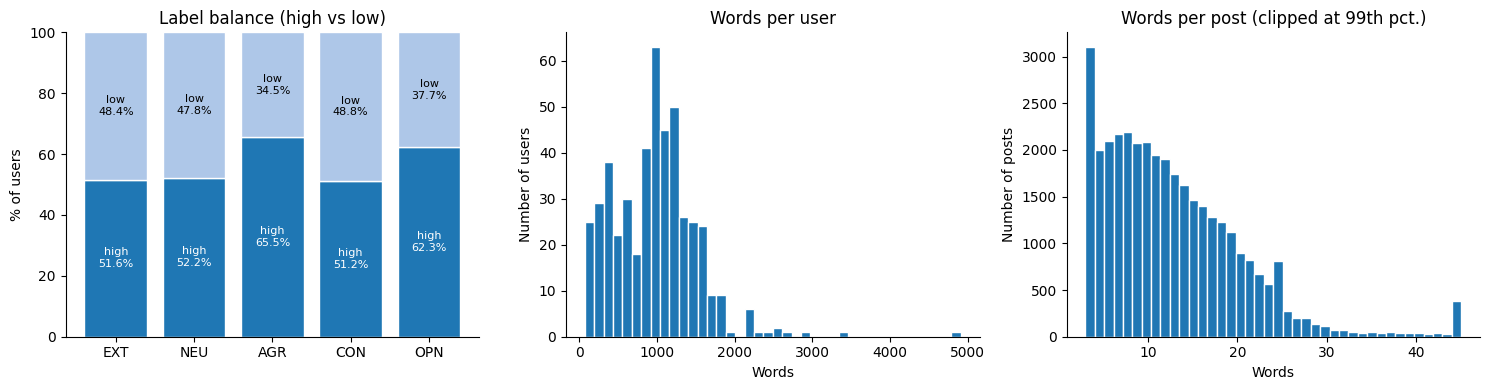

In [17]:
posts_df["n_words"] = posts_df["text_orig"].str.split().str.len()
ud = posts_df.groupby("user_id").agg(n_posts=("post_idx", "size"), words_user=("n_words", "sum"),
                                     words_post_mean=("n_words", "mean"))
stats = pd.DataFrame({
    "mean": [ud.n_posts.mean(), ud.words_user.mean(), posts_df.n_words.mean(), ud.words_post_mean.mean()],
    "sd":   [ud.n_posts.std(), ud.words_user.std(), posts_df.n_words.std(), ud.words_post_mean.std()],
    "median": [ud.n_posts.median(), ud.words_user.median(), posts_df.n_words.median(), ud.words_post_mean.median()],
}, index=["posts per user", "words per user", "words per post (all posts)", "words per post (user means)"]).round(2)
display(stats); savetab(stats, "length_statistics")

# Class balance of the five binary tasks: one row per trait, identical columns for all of them
rows = []
for col, (p1, p0) in DIMS.items():
    n1 = int(df[col].sum())
    n0 = len(df) - n1
    by_src = df.groupby("source")[col].mean() * 100
    rows.append({"dimension": col, "pole_1": p1, "pole_0": p0,
                 "n_1": n1, "n_0": n0,
                 "pct_1": n1 / len(df) * 100, "pct_0": n0 / len(df) * 100,
                 "majority_pole": p1 if n1 >= n0 else p0,
                 "majority_baseline_acc": max(n1, n0) / len(df),
                 **{f"pct_1_{s}": by_src.get(s, np.nan) for s in SOURCES}})
bal = pd.DataFrame(rows).set_index("dimension")
display(bal.round(3)); savetab(bal.round(4), "label_balance")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Label balance (% of users), stacked: pole coded 1 at the bottom, pole coded 0 on top
x = np.arange(len(bal))
b1 = axes[0].bar(x, bal["pct_1"], edgecolor="white", color="#1f77b4")
b0 = axes[0].bar(x, bal["pct_0"], bottom=bal["pct_1"], edgecolor="white", color="#aec7e8")
for i, (dim, r) in enumerate(bal.iterrows()):
    axes[0].text(i, r["pct_1"] / 2, f"{r['pole_1']}\n{r['pct_1']:.1f}%", ha="center", va="center", fontsize=8, color="white")
    axes[0].text(i, r["pct_1"] + r["pct_0"] / 2, f"{r['pole_0']}\n{r['pct_0']:.1f}%", ha="center", va="center", fontsize=8)
axes[0].set_xticks(x, bal.index)
axes[0].set(title="Label balance (high vs low)", ylabel="% of users", ylim=(0, 100))

axes[1].hist(ud.words_user, bins=40, edgecolor="white")
axes[1].set(title="Words per user", xlabel="Words", ylabel="Number of users")

axes[2].hist(posts_df.n_words.clip(upper=posts_df.n_words.quantile(0.99)), bins=40, edgecolor="white")
axes[2].set(title="Words per post (clipped at 99th pct.)", xlabel="Words", ylabel="Number of posts")
savefig("label_balance_and_length_distributions")

STEP FIVE: train/validation split

In [18]:
def _safe_strat(s, min_n=3):
    # profiles with fewer than min_n users are pooled so that stratification never fails
    s = s.where(s.map(s.value_counts()) >= min_n, "RARE")
    return s if s.value_counts().min() >= 2 else None

def stratified_user_split(users, strat, fractions, seed):
    # two-way split by user, stratified on the (platform, high/low profile) strata
    val_size = fractions["val"] / (fractions["train"] + fractions["val"])
    return train_test_split(users, test_size=val_size, stratify=_safe_strat(strat), random_state=seed)

def make_examples(posts_df, k):
    out, ex_id = [], 0
    for uid, g in posts_df.sort_values(["user_id", "post_idx"]).groupby("user_id", sort=False):
        o, m = g["text_orig"].tolist(), g["text_masked"].tolist()
        starts = list(range(0, len(o), k))
        if len(starts) > 1 and len(o) - starts[-1] < max(1, k // 2):
            starts = starts[:-1]
        for j, s in enumerate(starts):
            e = starts[j + 1] if j + 1 < len(starts) else len(o)
            out.append((f"e{ex_id:06d}", uid, j, " ".join(o[s:e]), " ".join(m[s:e]), m[s:e]))
            ex_id += 1
    return pd.DataFrame(out, columns=["ex_id", "user_id", "ex_idx", "text_orig", "text_masked", "posts_masked"])

# Split by user BEFORE building examples
users = df.set_index("user_id")["profile"]
tr, va = stratified_user_split(users, users, SPLIT, SEED)
assert not (set(tr.index) & set(va.index)), "Users shared between train and validation!"
split_of = {**{u: "train" for u in tr.index}, **{u: "val" for u in va.index}}
assert len(split_of) == len(df)
df["split"] = df["user_id"].map(split_of)
print(df["split"].value_counts().to_string())
savetab(df[["user_id", "source", "profile", "split"]], "user_split_assignment", index=False)

# share of "high" users per trait (and of Facebook users) in each split: stratification sanity check
chk = df.groupby("split")[list(DIMS)].mean().mul(100)
chk["facebook"] = df.groupby("split")["source"].apply(lambda s: (s == "facebook").mean() * 100)
chk = chk.round(1); display(chk); savetab(chk, "split_label_balance")

ex = make_examples(posts_df, EXAMPLE_POSTS)
ex = ex.merge(df[["user_id", "profile", "source", "split"] + list(DIMS)], on="user_id", how="left")
print(f"Examples: {len(ex):,} ({EXAMPLE_POSTS} posts each)")
display(ex.groupby("split").agg(users=("user_id", "nunique"), examples=("ex_id", "size")))

split
train    328
val      141


,EXT,NEU,AGR,CON,OPN,facebook
split,,,,,,
train,52.1,52.1,65.9,50.9,61.6,37.2
val,50.4,52.5,64.5,51.8,63.8,37.6


Examples: 3,543 (10 posts each)


,users,examples
split,,
train,328,2465
val,141,1078


STEP SIX: baseline

In [19]:
tr_ex = ex[ex.split == "train"]
imb = []
for col, (p1, p0) in DIMS.items():
    n1, n0 = int(tr_ex[col].sum()), int((1 - tr_ex[col]).sum())
    imb.append(dict(dimension=col, train_examples_1=n1, train_examples_0=n0,
                    minority=p1 if n1 < n0 else p0, deficit=abs(n1 - n0),
                    needed_synthetic=min(MAX_SYN_PER_DIM, int(abs(n1 - n0) * TARGET_BALANCE))))
imb = pd.DataFrame(imb).set_index("dimension"); display(imb); savetab(imb, "imbalance_and_synthetic_budget")

,train_examples_1,train_examples_0,minority,deficit,needed_synthetic
dimension,,,,,
EXT,1315,1150,low,165,165
NEU,1292,1173,low,119,119
AGR,1638,827,low,811,811
CON,1210,1255,high,45,45
OPN,1575,890,low,685,685


## STEP SEVEN: oversampling with fine-tuning

Fine-Tuning GPT-2 on the train set:

In [20]:
import torch

print("CUDA disponibile:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU allocata:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("Memoria GPU riservata:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

CUDA disponibile: True
GPU: Tesla T4
Memoria GPU allocata: 0.0 GB
Memoria GPU riservata: 0.0 GB


In [21]:
from transformers import get_linear_schedule_with_warmup
import gc
import torch

assert set(tr_ex["user_id"]) <= set(tr.index), "Fine-tuning data must come from training users only!"

# Free up as much memory as possible before loading
gc.collect()
torch.cuda.empty_cache()

if (FT_DIR / "config.json").exists():
    print("Loading the fine-tuned model from", FT_DIR)
    # Load with low_cpu_mem_usage to save system RAM
    gen_model = AutoModelForCausalLM.from_pretrained(FT_DIR, low_cpu_mem_usage=True)
else:
    ft_src = tr_ex if FT_MAX_EXAMPLES is None else tr_ex.sample(min(FT_MAX_EXAMPLES, len(tr_ex)), random_state=SEED)
    ft_texts = [f"{make_ctrl(r)} {r['text_masked']}{tok.eos_token}" for r in ft_src.to_dict("records")]
    val_src = ex[ex.split == "val"].sample(min(FT_PPL_SAMPLE, int((ex.split == "val").sum())), random_state=SEED)
    val_texts = [f"{make_ctrl(r)} {r['text_masked']}{tok.eos_token}" for r in val_src.to_dict("records")]
    print(f"Fine-tuning on {len(ft_texts):,} training examples ({FT_EPOCHS} epochs)")
    gen_model = finetune_gpt2(ft_texts, val_texts)
    gen_model.save_pretrained(FT_DIR); tok.save_pretrained(FT_DIR)

if DEVICE == "cuda":
    gen_model = gen_model.half()
gen_model = gen_model.to(DEVICE).eval()
gc.collect(); torch.cuda.empty_cache()

# qualitative check: texts generated from the control codes alone (all traits high vs all traits low, per platform)
for src in SOURCES:
    for lvl in (1, 0):
        print(f"[{src} | all traits {'high' if lvl else 'low'}]")
        for g in generate_batch([make_ctrl({"source": src, **{x: lvl for x in TRAITS}})] * 3):
            print("  -", g.strip()[:250])

Fine-tuning on 2,465 training examples (2 epochs)


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

Validation perplexity BEFORE fine-tuning: 155.9


/tmp/ipykernel_576/2653132805.py:153: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_576/2653132805.py:166: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); sched.step()


Validation perplexity after epoch 1: 69.4
  epoch 2/2 | step 250/310 | loss 4.354 | 2.0 min
Validation perplexity after epoch 2: 66.5


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[facebook | all traits high]
  - @username @NAME @NL: #NerdDuty - #IWillSeeYou #RideOn @NadirLincoln #NL @nl: @nadirs #ride
  - @username what's up with the new @#$% URL #pics @ username @ URL @< @* @$ URL via @: URL
  - What are the chances of that happening? URL #fb #facebook #twitter @username @ username @ URL How many people have #username on twitter? How do you know about this? @#$%
[facebook | all traits low]
  - @username @user I don't know, but I'll be a fan of @bob's @me :/ @Bob: @Me: I'm not a follower of him, I
  - @username @u-username I'm at the beach... I have a whole bunch of questions for you. I've been on the road for a long time. URL #SATURDAY URL
  - @username @sadly, you should only ever use the word "chosen" on your site URL #chose #username #wisdom - #lily #life #learning URL @
[twitter | all traits high]
  - @username @user @User I love you. I like your art. And I think you should go see another movie, but I don't think I'd be able to see it. @users
  - If anyone

In [22]:
# one pass per dimension (each call can be interrupted and re-run)
for k, dim in enumerate(DIMS):
    generate_synthetic(dim, k)

# sanity checks: synthetic data only derive from training users
syn = {}
for dim in DIMS:
    f = AUG_DIR / f"syn_{dim}.csv"
    if f.exists():
        syn[dim] = pd.read_csv(f)
        assert set(syn[dim]["source_user_id"]) <= set(tr.index), "Synthetic data from a non-training user!"
print({d: len(s) for d, s in syn.items()})
first = next(iter(syn), None)
display(syn[first].sample(min(3, len(syn[first])), random_state=SEED)[["label", "text_masked"]] if first else "no synthetic data")

[EXT] needed=165 | already done=0 | minority label=0
  165/165 | kept 142/165 | 0.1 min elapsed
[NEU] needed=119 | already done=0 | minority label=0
  119/119 | kept 104/119 | 0.1 min elapsed
[AGR] needed=811 | already done=0 | minority label=0
  811/811 | kept 678/811 | 0.5 min elapsed
[CON] needed=45 | already done=0 | minority label=1
  45/45 | kept 42/45 | 0.0 min elapsed
[OPN] needed=685 | already done=0 | minority label=0
  685/685 | kept 529/685 | 0.4 min elapsed
{'EXT': 142, 'NEU': 104, 'AGR': 678, 'CON': 42, 'OPN': 529}


,label,text_masked
141,0,#Hercules #Maniac #Culture #Fashion #Tournamen...
121,0,"""I am a good kisser, I am beautiful, and I sha..."
46,0,"you should absolutely listen, I've Got A New W..."


Memorisation check:

In [23]:
def shingles(text, n=8):
    w = text.lower().split()
    return {hash(" ".join(w[i:i + n])) for i in range(max(0, len(w) - n + 1))}

train_sh = set()
for t in tr_ex["text_masked"].sample(min(len(tr_ex), 5000), random_state=SEED):
    train_sh |= shingles(t)

mem_rows = []
for dim, s in syn.items():
    smp = s.sample(min(len(s), 1000), random_state=SEED)
    ov = []
    for t in smp["text_masked"]:
        sh = shingles(t)
        ov.append(len(sh & train_sh) / len(sh) if sh else 0.0)
    ov = np.array(ov)
    mem_rows.append(dict(dimension=dim, n_synthetic=len(s),
                         pct_exact_duplicates=s["text_masked"].duplicated().mean() * 100,
                         mean_shingle_overlap=ov.mean(), pct_texts_overlap_gt_50=(ov > 0.5).mean() * 100))
if mem_rows:
    mem = pd.DataFrame(mem_rows).set_index("dimension").round(3)
    display(mem); savetab(mem, "synthetic_memorisation_check")
else:
    print("No synthetic data: memorisation check skipped")
del train_sh; gc.collect()

,n_synthetic,pct_exact_duplicates,mean_shingle_overlap,pct_texts_overlap_gt_50
dimension,,,,
EXT,142,0.0,0.0,0.0
NEU,104,0.0,0.0,0.0
AGR,678,0.0,0.0,0.0
CON,42,0.0,0.0,0.0
OPN,529,0.0,0.0,0.0


0

## STEP EIGHT: robustness evaluation

done: original    EXT
done: masked      EXT
done: masked+LLM  EXT
done: original    NEU
done: masked      NEU
done: masked+LLM  NEU
done: original    AGR
done: masked      AGR
done: masked+LLM  AGR
done: original    CON
done: masked      CON
done: masked+LLM  CON
done: original    OPN
done: masked      OPN
done: masked+LLM  OPN


condition,masked,masked+LLM,original
dimension,,,
AGR,0.525,0.697,0.525
CON,0.730,0.745,0.730
EXT,0.691,0.740,0.691
NEU,0.660,0.647,0.660
OPN,0.549,0.664,0.549
mean,0.631,0.699,0.631


Majority-class macro-F1 on test (example level):
 dimension
EXT    0.354
NEU    0.354
AGR    0.422
CON    0.329
OPN    0.423


,macro-F1 gap (original - masked)
dimension,
AGR,0.0
CON,0.0
EXT,0.0
NEU,0.0
OPN,0.0
mean,0.0


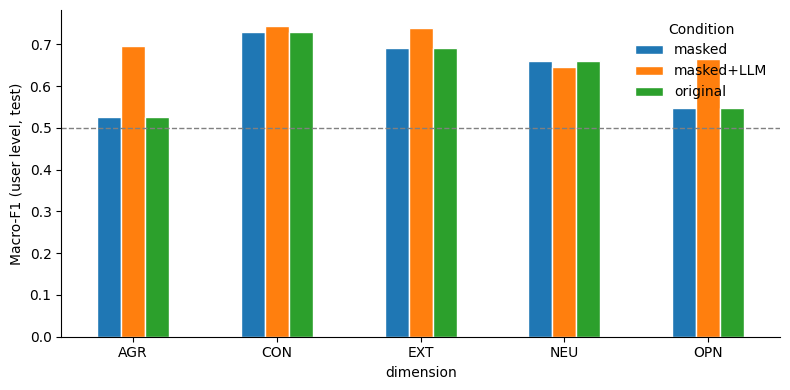

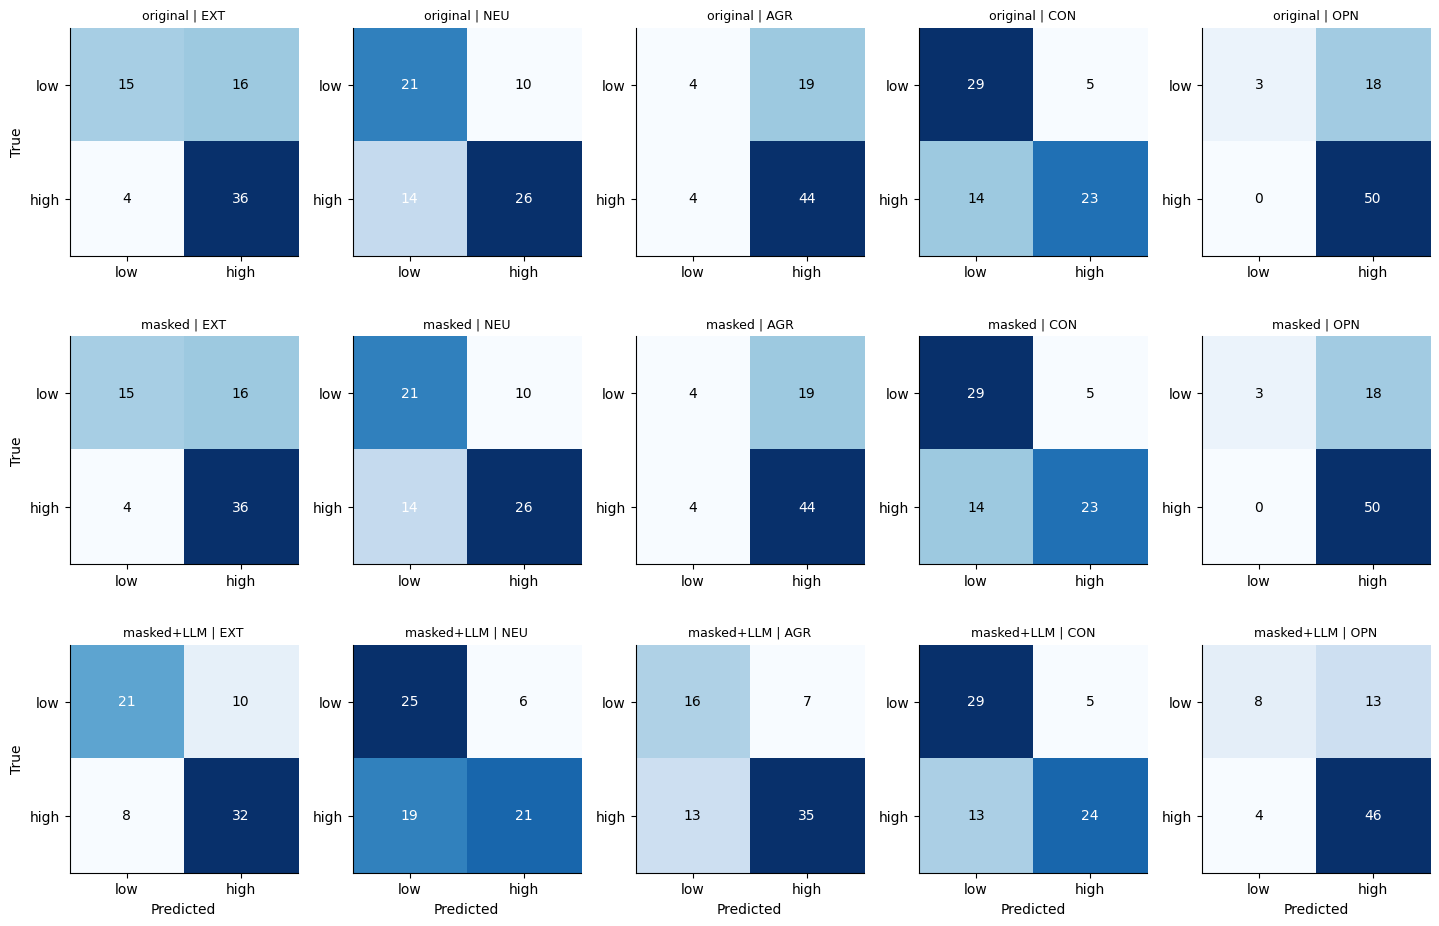

In [24]:
CONDITIONS = [("original", "text_orig", False), ("masked", "text_masked", False), ("masked+LLM", "text_masked", True)]
val_ex, test_ex = ex[ex.split == "val"], ex[ex.split == "test"]

# Fix: If test split is empty, split the validation set into 50/50 val and test sets
if len(test_ex) == 0 and len(val_ex) > 0:
    unique_val_users = val_ex["user_id"].unique()
    np.random.seed(SEED)
    val_users, test_users = train_test_split(unique_val_users, test_size=0.5, random_state=SEED)
    test_ex = val_ex[val_ex["user_id"].isin(test_users)].copy()
    val_ex = val_ex[val_ex["user_id"].isin(val_users)].copy()
    # Update split column for correct grouping
    val_ex["split"] = "val"
    test_ex["split"] = "test"

results, cms, vec_cache = [], {}, {}

for col, (p1, p0) in DIMS.items():
    dname = col
    for split_name, sdf in (("val", val_ex), ("test", test_ex)):
        if len(sdf) == 0: continue
        mb = majority_baseline(tr_ex[col], sdf[col])
        results.append(dict(condition="majority", dimension=dname, split=split_name, level="example", **mb))
    for cond, tcol, use_aug in CONDITIONS:
        if use_aug and col not in syn:
            continue
        X_text = tr_ex[tcol].tolist(); y = tr_ex[col].values
        if use_aug:
            X_text = X_text + syn[col]["text_masked"].tolist(); y = np.concatenate([y, syn[col]["label"].values])
        if use_aug or cond not in vec_cache:
            vec = TfidfVectorizer(**TFIDF_KW); Xtr = vec.fit_transform(X_text)
            if not use_aug: vec_cache[cond] = (vec, Xtr)
        else:
            vec, Xtr = vec_cache[cond]
        clf = LogisticRegression(C=CLF_C, max_iter=2000, solver="liblinear", random_state=SEED).fit(Xtr, y)
        for split_name, sdf in (("val", val_ex), ("test", test_ex)):
            if len(sdf) == 0: continue
            p = clf.predict_proba(vec.transform(sdf[tcol]))[:, 1]
            results.append(dict(condition=cond, dimension=dname, split=split_name, level="example",
                                train_size=len(y), **metrics(sdf[col].values, (p >= 0.5).astype(int))))
            yu, pu = user_level(sdf, p, col)
            results.append(dict(condition=cond, dimension=dname, split=split_name, level="user",
                                train_size=len(y), **metrics(yu, pu)))
            if split_name == "test":
                cms[(cond, dname)] = confusion_matrix(yu, pu, labels=[0, 1])
        print(f"done: {cond:11s} {dname}")
    gc.collect()

res = pd.DataFrame(results)
res["trait_name"] = res["dimension"].map(TRAIT_NAMES)
savetab(res.round(4), "evaluation_results", index=False)

# summary: macro-F1 on the user-level test set
summ = res[(res.split == "test") & (res.level == "user")].pivot(index="dimension", columns="condition", values="macro_f1")
summ.loc["mean"] = summ.mean()
display(summ.round(3)); savetab(summ.round(4), "summary_test_macroF1_user_level")

base = res[(res.condition == "majority") & (res.split == "test")].set_index("dimension")["macro_f1"]
print("Majority-class macro-F1 on test (example level):\n", base.round(3).to_string())

if {"original", "masked"} <= set(summ.columns):
    gap = (summ["original"] - summ["masked"]).rename("macro-F1 gap (original - masked)")
    display(gap.round(3).to_frame())

summ.drop(index="mean").plot(kind="bar", figsize=(8, 4), edgecolor="white")
plt.ylabel("Macro-F1 (user level, test)"); plt.xticks(rotation=0); plt.axhline(0.5, ls="--", c="gray", lw=1)
plt.legend(frameon=False, title="Condition"); savefig("macroF1_by_condition")

# confusion matrices (user level, test)
conds = [c for c, _, a in CONDITIONS if any((c, d) in cms for d in DIMS)]
fig, axes = plt.subplots(len(conds), len(DIMS), figsize=(2.9 * len(DIMS), 3.2 * len(conds)), squeeze=False)
for i, cond in enumerate(conds):
    for j, (col, (p1, p0)) in enumerate(DIMS.items()):
        ax = axes[i][j]
        if (cond, col) not in cms:
            ax.axis("off"); continue
        cm = cms[(cond, col)]
        ax.imshow(cm, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1], [p0, p1]); ax.set_yticks([0, 1], [p0, p1])
        ax.set_title(f"{cond} | {col}", fontsize=9)
        if j == 0: ax.set_ylabel("True")
        if i == len(conds) - 1: ax.set_xlabel("Predicted")
savefig("confusion_matrices_test_user_level")

Preparing the file for GitHub commit:

In [25]:
!pip -q install nbstripout

SRC = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/PREPROCESSING: masking.ipynb"
DST = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/GIT_READY/PREPROCESSING_masking.ipynb"

!mkdir -p "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/GIT_READY"
!cp "{SRC}" "{DST}"
!nbstripout --extra-keys "metadata.colab cell.metadata.colab cell.metadata.executionInfo cell.metadata.outputId" "{DST}"
!grep -c "displayName\|userId" "{DST}"
!grep -c '"outputs": \[\]' "{DST}"

1
7
